In [ ]:
"""Count SimNIBS mesh element tags across simulation steps.

Each unique mesh file is one observation, including multiple electrode
configurations, thresholds, ASF values, datasets, and simulation runs for
one subject at the same step.

For UQ HDF5 files, hdf5_group='mesh' reads the full mesh; 'mesh_roi'
may exclude scalp tissue tags. Percentages are *element counts*, not
volume-weighted tissue fractions.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import simnibs
from tqdm.auto import tqdm


def _simulation_path(mesh_path: str, step: str) -> str:
    """Find the simulation directory above step_N, for stable plot jitter."""
    parent = Path(mesh_path).parent
    return str(parent.parent if parent.name == step else parent)


def summarize_element_tags(
    df_query: pd.DataFrame,
    *,
    model_type: str,
    filename: str = "tdcs_uq_gpc.hdf5",
    hdf5_group: str = "mesh",
    elm_type: int | None = None,
) -> pd.DataFrame:
    """Return one row per unique mesh file and tag, with all query metadata.

    Tags absent from an individual mesh receive zero counts.
    elm_type=None counts all elements (triangles and tetrahedra).
    elm_type=4 counts tetrahedra; elm_type=2 counts triangles.
    """
    if model_type not in {"skin_single", "skin_double"}:
        raise ValueError(f"Invalid model_type: {model_type!r}")
    if elm_type not in {None, 2, 4}:
        raise ValueError("elm_type must be None (all), 2 (triangles), or 4 (tetrahedra)")

    required = {"subject_dir", "model_type_dir", "step", "electrode_configuration", "full_file_path"}
    missing = required - set(df_query.columns)
    if missing:
        raise ValueError(f"Missing query columns: {sorted(missing)}")

    frame = df_query.loc[df_query["model_type_dir"].eq(model_type)].copy()
    frame = frame.loc[frame["full_file_path"].notna()]
    frame = frame.loc[frame["full_file_path"].map(lambda p: Path(str(p)).name == filename)].copy()
    if frame.empty:
        raise ValueError(f"No {filename!r} rows for {model_type!r}. Query the mesh file, not a NIfTI.")
    if frame[list(required)].isna().any().any():
        raise ValueError("Query includes null values in required columns")
    if not frame["electrode_configuration"].map(lambda value: isinstance(value, str) and bool(value.strip())).all():
        raise ValueError("electrode_configuration must contain nonempty string labels")
    frame["electrode_configuration"] = frame["electrode_configuration"].str.strip().str.upper()

    valid_steps = frame["step"].astype(str).str.fullmatch(r"step_\d+")
    if not valid_steps.all():
        raise ValueError(f"Invalid step names: {frame.loc[~valid_steps, 'step'].unique().tolist()}")
    frame["step_num"] = frame["step"].str.removeprefix("step_").astype(int)
    frame["subjid"] = frame["subject_dir"].map(lambda p: Path(str(p)).name)

    # The file path identifies one simulation result at one step. Never collapse
    # separate thresholds, ASF values, montages, datasets, or repeated runs.
    duplicates = frame.duplicated("full_file_path", keep=False)
    if duplicates.any():
        examples = frame.loc[duplicates, "full_file_path"].head(12).to_list()
        raise ValueError(f"The same mesh file appears multiple times in df_query: {examples}")

    frame = frame.sort_values(["step_num", "subjid", "electrode_configuration", "full_file_path"]).reset_index(drop=True)
    frame.insert(0, "mesh_id", np.arange(len(frame), dtype=np.int64))
    frame["mesh_path"] = frame["full_file_path"].astype(str)
    frame["simulation_path"] = [_simulation_path(p, s) for p, s in zip(frame["mesh_path"], frame["step"], strict=True)]

    mesh_totals = []
    tag_counts = []
    for row in tqdm(frame.itertuples(index=False), total=len(frame), desc=f"Tags: {model_type}"):
        path = Path(row.full_file_path)
        if not path.is_file():
            raise FileNotFoundError(f"Missing mesh: {path}")
        try:
            if path.suffix.lower() in {".hdf5", ".h5"}:
                mesh = simnibs.Msh.read_hdf5(str(path), hdf5_group, load_data=False)
            elif path.suffix.lower() == ".msh":
                mesh = simnibs.read_msh(str(path))
            else:
                raise ValueError(f"Unsupported mesh file extension: {path}")
            tag_values = np.asarray(mesh.elm.tag1).reshape(-1)
            if elm_type is not None:
                element_types = np.asarray(mesh.elm.elm_type).reshape(-1)
                if element_types.size != tag_values.size:
                    raise ValueError("Element-type and tag arrays have different lengths")
                tag_values = tag_values[element_types == elm_type]
        except Exception as exc:
            raise RuntimeError(f"Could not read element tags from {path} (group={hdf5_group!r})") from exc

        if tag_values.size == 0:
            raise ValueError(f"No selected elements in {path} (elm_type={elm_type})")
        tags, counts = np.unique(tag_values, return_counts=True)
        mesh_totals.append({"mesh_id": row.mesh_id, "n_total": int(tag_values.size)})
        tag_counts.extend({"mesh_id": row.mesh_id, "tag": int(tag), "n_tag": int(count)} for tag, count in zip(tags, counts, strict=True))

    meshes = frame.merge(pd.DataFrame.from_records(mesh_totals), on="mesh_id", validate="one_to_one")
    counts = pd.DataFrame.from_records(tag_counts)
    tag_space = pd.DataFrame({"tag": sorted(counts["tag"].unique())})
    result = meshes.merge(tag_space, how="cross")
    result = result.merge(counts, on=["mesh_id", "tag"], how="left", validate="one_to_one")
    result["n_tag"] = result["n_tag"].fillna(0).astype(np.int64)
    result["fraction"] = result["n_tag"] / result["n_total"]
    result["percent"] = 100.0 * result["fraction"]

    totals = result.groupby("mesh_id", sort=False)["n_tag"].transform("sum")
    if not totals.eq(result["n_total"]).all():
        raise RuntimeError("Tag counts do not sum to the total element count")
    return result.sort_values(["step_num", "subjid", "electrode_configuration", "mesh_id", "tag"]).reset_index(drop=True)


def plot_tag_distribution(df_tags: pd.DataFrame, *, tag: int):
    """Plot each simulation mesh as a dot and a violin of mesh fractions per step."""
    data = df_tags.loc[df_tags["tag"].eq(tag)].copy()
    if data.empty:
        raise ValueError(f"Tag {tag} not found anywhere in the analyzed meshes")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    rng = np.random.default_rng(0)
    simulation_paths = sorted(data["simulation_path"].unique())
    offsets = dict(zip(simulation_paths, rng.uniform(-0.14, 0.14, len(simulation_paths)), strict=True))
    steps = sorted(data["step_num"].unique())

    for step, group in data.groupby("step_num", sort=True):
        values = group["percent"].to_numpy()
        if len(values) >= 2 and np.ptp(values) > 0:
            violin = ax.violinplot(values, positions=[step], widths=0.75, showmedians=True)
            for body in violin["bodies"]:
                body.set_alpha(0.25)
        positions = [step + offsets[simulation] for simulation in group["simulation_path"]]
        ax.scatter(positions, values, s=22, alpha=0.75, zorder=3)

    ax.set_xticks(steps)
    ax.set_xlabel("Simulation step")
    ax.set_ylabel(f"Elements with tag {tag} (% of selected elements)")
    ax.set_title(f"Element tag {tag} across simulation steps")
    fig.tight_layout()
    return fig, ax


query_csv = '/projects/p32903/Alex2/ect-results-tools/query_result_1.csv'
model_type = "skin_single"
tag_of_interest = 25

df_query = pd.read_csv(query_csv)

df_query = df_query[df_query['threshold']==90]
df_tags = summarize_element_tags(df_query, model_type=model_type, elm_type=None)
df_tags.to_csv(f"mesh_tags_{model_type}.csv", index=False)
samples = df_tags[["mesh_id", "subjid", "step_num"]].drop_duplicates()
print(samples.groupby("step_num").agg(n_subjects=("subjid", "nunique"), n_meshes=("mesh_id", "size")))
fig, _ = plot_tag_distribution(df_tags, tag=tag_of_interest)
fig.savefig(f"mesh_tag_{tag_of_interest}_{model_type}.png", dpi=200)
plt.show()


In [21]:
"""Count SimNIBS element tags and plot fractions of selected tag populations.

Each unique mesh is one observation, including multiple montages, thresholds,
ASF values, datasets, and simulation runs for the same subject and step.

For UQ HDF5 files, hdf5_group='mesh' reads the full mesh; 'mesh_roi' may
exclude scalp tags. Fractions are based on element counts, not tissue volumes.
"""

from numbers import Integral
from pathlib import Path
from typing import Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import simnibs
from tqdm.auto import tqdm


def _simulation_path(mesh_path: str, step: str) -> str:
    """Find the simulation directory above step_N, for stable plot jitter."""
    parent = Path(mesh_path).parent
    return str(parent.parent if parent.name == step else parent)


def _validate_tags(tags: Sequence[int] | None, *, name: str) -> tuple[int, ...] | None:
    """Validate tag selections without silently coercing invalid inputs."""
    if tags is None:
        return None
    if isinstance(tags, (str, bytes)):
        raise ValueError(f"{name} must be a sequence of integers, not a string")
    try:
        values = tuple(tags)
    except TypeError as exc:
        raise ValueError(f"{name} must be a sequence of integers") from exc
    if not values and name == "denominator_tags":
        raise ValueError("denominator_tags cannot be empty")
    if any(not isinstance(value, Integral) or isinstance(value, bool) for value in values):
        raise ValueError(f"{name} must contain integer element tags")
    if len(set(values)) != len(values):
        raise ValueError(f"{name} contains duplicate tags")
    return tuple(int(value) for value in values)


def summarize_element_tags(
    df_query: pd.DataFrame,
    *,
    model_type: str,
    filename: str = "tdcs_uq_gpc.hdf5",
    hdf5_group: str = "mesh",
    elm_type: int | None = None,
    denominator_tags: Sequence[int] | None = None,
    include_tags: Sequence[int] = (),
) -> pd.DataFrame:
    """Return one row per mesh and tag, with a configurable denominator.

    denominator_tags=(5, 13) calculates n_tag / (n_tag5 + n_tag13).
    denominator_tags=None uses the count of all selected elements (original behavior).
    include_tags=(25,) guarantees tag 25 appears with zero counts when absent.
    Every mesh keeps n_total (all selected elements) and n_total_denominator.

    elm_type=None counts triangles and tetrahedra; 4 counts tetrahedra only.
    Fractions are of *element counts*, not physical tissue volume.
    """
    if model_type not in {"skin_single", "skin_double"}:
        raise ValueError(f"Invalid model_type: {model_type!r}")
    if elm_type not in {None, 2, 4}:
        raise ValueError("elm_type must be None (all), 2 (triangles), or 4 (tetrahedra)")
    denominator_tags = _validate_tags(denominator_tags, name="denominator_tags")
    include_tags = _validate_tags(include_tags, name="include_tags")

    required = {"subject_dir", "model_type_dir", "step", "electrode_configuration", "full_file_path"}
    missing = required - set(df_query.columns)
    if missing:
        raise ValueError(f"Missing query columns: {sorted(missing)}")

    frame = df_query.loc[df_query["model_type_dir"].eq(model_type)].copy()
    frame = frame.loc[frame["full_file_path"].notna()]
    frame = frame.loc[frame["full_file_path"].map(lambda p: Path(str(p)).name == filename)].copy()
    if frame.empty:
        raise ValueError(f"No {filename!r} rows for {model_type!r}. Query the mesh file, not a NIfTI.")
    if frame[list(required)].isna().any().any():
        raise ValueError("Query includes null values in required columns")
    if not frame["electrode_configuration"].map(lambda value: isinstance(value, str) and bool(value.strip())).all():
        raise ValueError("electrode_configuration must contain nonempty string labels")
    frame["electrode_configuration"] = frame["electrode_configuration"].str.strip().str.upper()

    valid_steps = frame["step"].astype(str).str.fullmatch(r"step_\d+")
    if not valid_steps.all():
        raise ValueError(f"Invalid step names: {frame.loc[~valid_steps, 'step'].unique().tolist()}")
    frame["step_num"] = frame["step"].str.removeprefix("step_").astype(int)
    frame["subjid"] = frame["subject_dir"].map(lambda p: Path(str(p)).name)

    # The file path identifies one simulation result at one step. Never collapse
    # separate thresholds, ASF values, montages, datasets, or repeated runs.
    duplicates = frame.duplicated("full_file_path", keep=False)
    if duplicates.any():
        examples = frame.loc[duplicates, "full_file_path"].head(12).to_list()
        raise ValueError(f"The same mesh file appears multiple times in df_query: {examples}")

    frame = frame.sort_values(["step_num", "subjid", "electrode_configuration", "full_file_path"]).reset_index(drop=True)
    frame.insert(0, "mesh_id", np.arange(len(frame), dtype=np.int64))
    frame["mesh_path"] = frame["full_file_path"].astype(str)
    frame["simulation_path"] = [_simulation_path(p, s) for p, s in zip(frame["mesh_path"], frame["step"], strict=True)]

    mesh_totals = []
    tag_counts = []
    for row in tqdm(frame.itertuples(index=False), total=len(frame), desc=f"Tags: {model_type}"):
        path = Path(row.full_file_path)
        if not path.is_file():
            raise FileNotFoundError(f"Missing mesh: {path}")
        try:
            if path.suffix.lower() in {".hdf5", ".h5"}:
                mesh = simnibs.Msh.read_hdf5(str(path), hdf5_group, load_data=False)
            elif path.suffix.lower() == ".msh":
                mesh = simnibs.read_msh(str(path))
            else:
                raise ValueError(f"Unsupported mesh file extension: {path}")
            tag_values = np.asarray(mesh.elm.tag1).reshape(-1)
            if elm_type is not None:
                element_types = np.asarray(mesh.elm.elm_type).reshape(-1)
                if element_types.size != tag_values.size:
                    raise ValueError("Element-type and tag arrays have different lengths")
                tag_values = tag_values[element_types == elm_type]
        except Exception as exc:
            raise RuntimeError(f"Could not read element tags from {path} (group={hdf5_group!r})") from exc

        if tag_values.size == 0:
            raise ValueError(f"No selected elements in {path} (elm_type={elm_type})")
        tags, counts = np.unique(tag_values, return_counts=True)
        mesh_totals.append({"mesh_id": row.mesh_id, "n_total": int(tag_values.size)})
        tag_counts.extend({"mesh_id": row.mesh_id, "tag": int(tag), "n_tag": int(count)} for tag, count in zip(tags, counts, strict=True))

    meshes = frame.merge(pd.DataFrame.from_records(mesh_totals), on="mesh_id", validate="one_to_one")
    counts = pd.DataFrame.from_records(tag_counts)

    if denominator_tags is None:
        meshes["n_total_denominator"] = meshes["n_total"]
        meshes["denominator_tags"] = "all"
    else:
        denominator_counts = (counts.loc[counts["tag"].isin(denominator_tags)]
                              .groupby("mesh_id", sort=False)["n_tag"].sum()
                              .rename("n_total_denominator"))
        meshes = meshes.join(denominator_counts, on="mesh_id")
        meshes["n_total_denominator"] = meshes["n_total_denominator"].fillna(0).astype(np.int64)
        meshes["denominator_tags"] = ",".join(str(tag) for tag in denominator_tags)
        invalid = meshes["n_total_denominator"].eq(0)
        if invalid.any():
            examples = meshes.loc[invalid, ["subjid", "step", "mesh_path"]].head(12).to_string(index=False)
            raise ValueError(f"No denominator elements found for tags {denominator_tags} in some meshes:\n{examples}")

    all_tags = sorted(set(counts["tag"].tolist()).union(include_tags))
    tag_space = pd.DataFrame({"tag": all_tags})
    result = meshes.merge(tag_space, how="cross")
    result = result.merge(counts, on=["mesh_id", "tag"], how="left", validate="one_to_one")
    result["n_tag"] = result["n_tag"].fillna(0).astype(np.int64)
    result["fraction"] = result["n_tag"] / result["n_total_denominator"]
    result["percent"] = 100.0 * result["fraction"]

    totals = result.groupby("mesh_id", sort=False)["n_tag"].transform("sum")
    if not totals.eq(result["n_total"]).all():
        raise RuntimeError("Tag counts do not sum to the total element count")
    return result.sort_values(["step_num", "subjid", "electrode_configuration", "mesh_id", "tag"]).reset_index(drop=True)


def plot_tag_distribution(
    df_tags: pd.DataFrame, *, tag: int, tag_fraction: Sequence[int] | None = None, title_info:str=''
):
    """Plot one dot per mesh, with violin plots across simulation steps.

    If tag_fraction=(5, 25), plot 100 * n_tag / (n_tag5 + n_tag25)
    using the raw counts, regardless of the saved 'percent' column.
    If tag_fraction=None, use the 'percent' values from summarization.
    """
    fraction_tags = _validate_tags(tag_fraction, name="tag_fraction")
    if fraction_tags is None:
        data = df_tags.loc[df_tags["tag"].eq(tag)].copy()
        if data.empty:
            raise ValueError(f"Tag {tag} is absent from the table; use tag_fraction=({tag},) to include zeros")
        denominator_labels = data["denominator_tags"].unique() if "denominator_tags" in data else ["all"]
        if len(denominator_labels) != 1:
            raise ValueError("Cannot plot data calculated with different denominator_tags settings")
        denominator_label = denominator_labels[0]
        denominator_text = "all selected elements" if denominator_label == "all" else f"elements with tags {denominator_label}"
    else:
        if not fraction_tags:
            raise ValueError("tag_fraction cannot be empty")
        required = {"mesh_id", "tag", "n_tag", "n_total", "step_num", "simulation_path"}
        missing = required - set(df_tags.columns)
        if missing:
            raise ValueError(f"Missing columns needed for tag_fraction: {sorted(missing)}")
        if df_tags.empty:
            raise ValueError("df_tags is empty")
        if df_tags.duplicated(["mesh_id", "tag"]).any():
            raise ValueError("df_tags contains duplicate mesh_id/tag rows")

        # Full tag counts are required: filtering the input table to one tag
        # would silently underestimate the denominator otherwise.
        data = df_tags.drop_duplicates("mesh_id").copy()
        totals = df_tags.groupby("mesh_id")["n_tag"].sum()
        expected = data.set_index("mesh_id")["n_total"]
        if not totals.eq(expected).all():
            raise ValueError("df_tags must contain all tag rows for each mesh; do not filter it by tag before plotting")

        numerator = df_tags.loc[df_tags["tag"].eq(tag)].set_index("mesh_id")["n_tag"]
        denominator = df_tags.loc[df_tags["tag"].isin(fraction_tags)].groupby("mesh_id")["n_tag"].sum()
        data["n_tag"] = data["mesh_id"].map(numerator).fillna(0).astype(np.int64)
        data["n_total_denominator"] = data["mesh_id"].map(denominator).fillna(0).astype(np.int64)
        invalid = data["n_total_denominator"].eq(0)
        if invalid.any():
            columns = [c for c in ["subjid", "step", "mesh_path"] if c in data]
            examples = data.loc[invalid, columns].head(12).to_string(index=False)
            raise ValueError(f"No elements with denominator tags {fraction_tags} in some meshes:\n{examples}")

        data["percent"] = 100.0 * data["n_tag"] / data["n_total_denominator"]
        denominator_text = f"elements with tags {', '.join(map(str, fraction_tags))}"

    fig, ax = plt.subplots(figsize=(8, 4.5))
    rng = np.random.default_rng(0)
    simulation_paths = sorted(data["simulation_path"].unique())
    offsets = dict(zip(simulation_paths, rng.uniform(-0.14, 0.14, len(simulation_paths)), strict=True))
    steps = sorted(data["step_num"].unique())

    for step, group in data.groupby("step_num", sort=True):
        values = group["percent"].to_numpy()
        if len(values) >= 2 and np.ptp(values) > 0:
            violin = ax.violinplot(values, positions=[step], widths=0.75, showmedians=True)
            for body in violin["bodies"]:
                body.set_alpha(0.25)
        positions = [step + offsets[simulation] for simulation in group["simulation_path"]]
        ax.scatter(positions, values, s=22, alpha=0.75, zorder=3)

    ax.set_xticks(steps)
    ax.set_xlabel("Simulation step")
    ax.set_ylabel(f"Tag {tag} (% of {denominator_text})")
    title_msg = f"Element tag {tag} across simulation steps"
    if title_info is not None: 
        title_msg += f" ({title_info})"
    ax.set_title(title_msg)
    fig.tight_layout()
    return fig, ax


# if __name__ == "__main__":
#     query_csv = "query_results.csv"
#     model_type = "skin_double"
#     tag_of_interest = 25
#     tag_fraction = [5, 25]  # Base scalp tag 5 and adaptive scalp tag 25.

#     df_query = pd.read_csv(query_csv)
#     df_tags = summarize_element_tags(
#         df_query, model_type=model_type, elm_type=4,
#         include_tags=(tag_of_interest,),
#     )
#     df_tags.to_csv(f"mesh_tags_{model_type}.csv", index=False)
#     samples = df_tags[["mesh_id", "subjid", "step_num"]].drop_duplicates()
#     print(samples.groupby("step_num").agg(n_subjects=("subjid", "nunique"), n_meshes=("mesh_id", "size")))
#     fig, _ = plot_tag_distribution(df_tags, tag=tag_of_interest, tag_fraction=tag_fraction)
#     fig.savefig(f"mesh_tag_{tag_of_interest}_{model_type}.png", dpi=200)
#     plt.show()


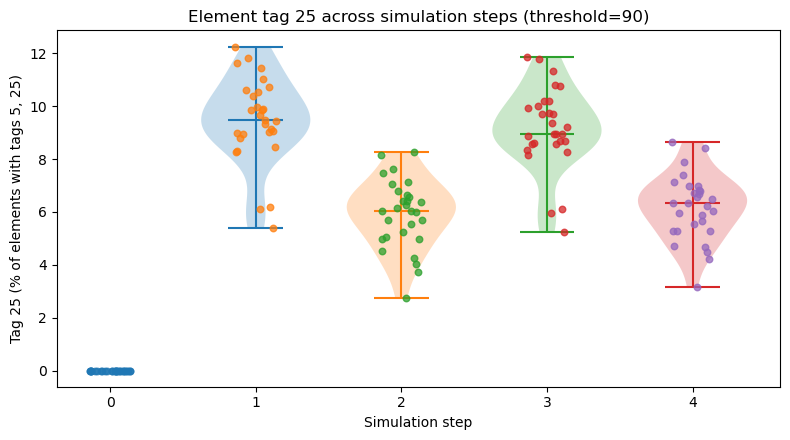

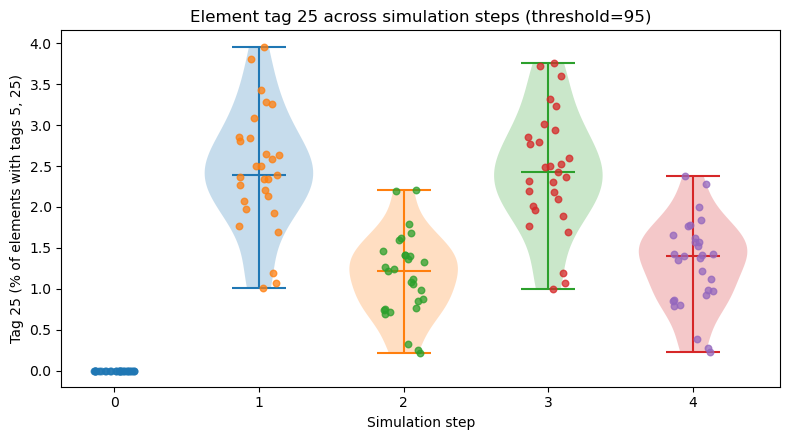

In [22]:
df90 = df_tags[df_tags['threshold']==90].copy()
fig, ax = plot_tag_distribution(
    df90,
    tag=25,
    tag_fraction=[5, 25],
    title_info='threshold=90'
)

df95 = df_tags[df_tags['threshold']==95].copy()
fig, ax = plot_tag_distribution(
    df95,
    tag=25,
    tag_fraction=[5, 25],
    title_info="threshold=95"
)
